# Notebook 2: Physics Simulation and Robot Loading

**Learning Objectives:**
1. Load real robots into Drake using `Parser` and pre-specified robot files (URDF, SDF, MJCF)
2. Understand Drake's physics simulation engine (`MultibodyPlant`) and the geometry engine (`SceneGraph`)
3.  Create custom 3D assets (your initials!) and learn `URDF` and `SDF` authoring
4. Visualize robots, objects, and simulations using Meshcat
5. Build complete robot simulations with custom objects in Drake

**What you'll build:** A complete simulation featuring the IIWA14 robot arm interacting with your custom initials asset!

---


## Setup and Imports

Let us first import Drake functionality for physics simulation, robot loading, and visualization.


In [1]:
import sys

if "google.colab" in sys.modules:
    %pip install -q manipulation[grader,letter]

In [2]:
from pathlib import Path

import numpy as np
from pydrake.all import (
    AddMultibodyPlantSceneGraph,
    BasicVector,
    Context,
    Diagram,
    DiagramBuilder,
    LeafSystem,
    MeshcatVisualizer,
    ModelInstanceIndex,
    MultibodyPlant,
    Parser,
    RigidTransform,
    Simulator,
)
from pydrake.visualization import ModelVisualizer

from manipulation import running_as_notebook
from manipulation.exercises.grader import Grader
from manipulation.exercises.intro.test_physics_simulation_and_robots import (
    TestPhysicsSimulationDiagramStructure,
    TestPhysicsSimulationFullSystem,
    TestPhysicsSimulationSimpleController,
    TestPhysicsSimulationVerification,
)
from manipulation.letter_generation import create_sdf_asset_from_letter
from manipulation.meshcat_utils import StartMeshcat
from manipulation.utils import RenderDiagram

## Meshcat Visualization

Before we start, let us set up Meshcat, our visualization tool.

**Meshcat** is Drake's primary 3D visualization tool that runs in your web browser. It provides real-time interactive visualization of robots, objects, and simulation environments. Meshcat lets you:

- **Visualize 3D robots and scenes** with proper geometry and textures
- **View simulations in real-time** as they run
- **Interact with the 3D scene** (rotate, zoom, pan) 
- **Record videos** for homework submissions
- **Debug your simulations** by seeing what's actually happening

You will find yourself frequently using meshcat to visualize and debug your code!


In [3]:
# Start meshcat for visualization
meshcat = StartMeshcat()

INFO:drake:Meshcat listening for connections at http://localhost:7001


**Click the link above to open Meshcat in your browser! We will use the same Meshcat window throughout this notebook, so keep it open!**

---

## Part 1: Loading the IIWA14 Robot

First, let's load a real robot! The **IIWA14** is a 7-DOF industrial robot arm from KUKA. Drake includes many robot models that you can load directly from Drake, which is what we will do in this part. You can find a full list of the available Drake models [here](https://github.com/RobotLocomotion/models).

**YOUR TASK:** Load and visualize the IIWA14 robot using Drake's physics engine.

**Key Concepts:**
- `Parser`: Loads robots or assets described with robot description files (like URDF/SDF/MJCF) files into the physics engine
- `MultibodyPlant`: Drake's main physics simulation engine for robots and objects. This will be the backbone for all of our simulations.
- `SceneGraph`: Drake's module for handling everything related to registering robot and object geometries, handling geometry queries, collision detection, etc.
- **Base Welding**: Fixing the robot base to the world frame is important so it doesn't fall!

**Reference:** For this part, we will closely follow the [Drake Simulation example](https://colab.research.google.com/github/RussTedrake/manipulation/blob/master/book/robot/simulation.ipynb) from [Chapter 2](https://manipulation.csail.mit.edu/robot.html) from the class textbook - in this part we will follow the **"Simulating the (passive) iiwa"** and **"Visualizing the scene"** sections closely. You should skim through those before you start the implementations below!

In [4]:
IIWA_URDF = "package://drake_models/iiwa_description/urdf/iiwa14_primitive_collision.urdf"


def create_IIWA14_diagram() -> tuple[Diagram, MultibodyPlant, ModelInstanceIndex]:
    builder = DiagramBuilder()
    plant, scene_graph = AddMultibodyPlantSceneGraph(builder, time_step=1e-4)

    parser = Parser(plant)
    (iiwa,) = parser.AddModelsFromUrl(IIWA_URDF)
    plant.WeldFrames(plant.world_frame(), plant.GetFrameByName("iiwa_link_0", iiwa))

    MeshcatVisualizer.AddToBuilder(builder, scene_graph, meshcat)

    plant.Finalize()
    diagram = builder.Build()
    return diagram, plant, iiwa


diagram, plant, iiwa = create_IIWA14_diagram()


In the code above, we used a different model than the model in the tutorial, because we wanted a model with collision geometry. In general, there are many available models for Drake that you can use out of the box. All the models can be found at this [Github repo](https://github.com/RobotLocomotion/models), and the url you provide to Parser follows this format `package://drake_models/{file path in "models" repo}`.

Test your code with the block below:

In [5]:
Grader.grade_output([TestPhysicsSimulationDiagramStructure], [locals()], "results.json")
Grader.print_test_results("results.json")

Total score is 10/10.

Score for Test IIWA14 diagram creation and structure is 10/10.


**Let us also visualize the block diagram, so you can have a look at the whole setup!**

- Notice that `MultibodyPlant`, `SceneGraph`, and `MeshcatVisualizer` are all systems in the block diagram.
- Make sure to have a look at the connections between the ports of the systems!

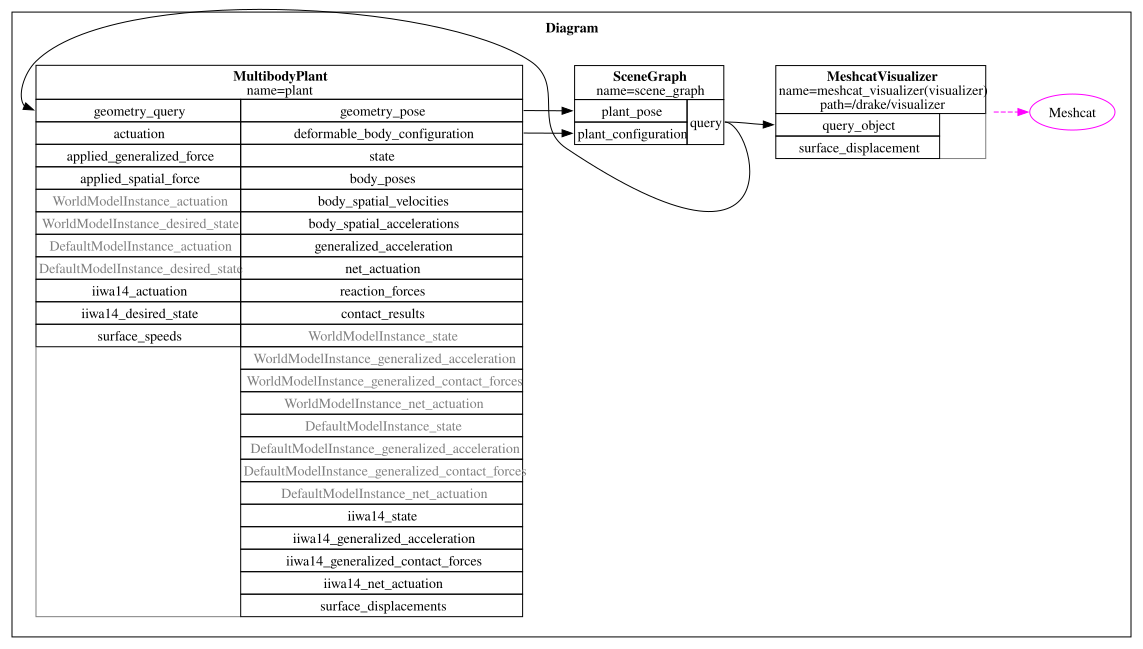

In [6]:
RenderDiagram(diagram, max_depth=1)

Let us also make a default context for the diagram, and have a look at it, just so we have a sense of what is going on!

**Reminder:** Remember that the context stores the "entire state", or all the dynamical information, of everything in the diagram, such as dynamical states of each system, simulation time, etc.

In [7]:
# Create a diagram context and print it
diagram_context = diagram.CreateDefaultContext()
print(diagram_context)


::_ Context (of a Diagram)
---------------------------
14 total discrete states in 1 groups
1 total abstract states
261 total numeric parameters in 47 groups
16 total abstract parameters

::_::plant Context
-------------------
Time: 0
States:
  1 discrete state groups with
     14 states
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
  1 abstract states

Parameters:
  47 numeric parameter groups with
     0 parameters
       []
     1 parameters
       [0.5]
     1 parameters
       [0.5]
     1 parameters
       [0.5]
     1 parameters
       [0.5]
     1 parameters
       [0.5]
     1 parameters
       [0.5]
     1 parameters
       [0.5]
     0 parameters
       []
     0 parameters
       []
     0 parameters
       []
     1 parameters
       [0.0001321]
     1 parameters
       [160]
     1 parameters
       [0.0001321]
     1 parameters
       [160]
     1 parameters
       [0.0001321]
     1 parameters
       [160]
     1 parameters
       [0.0001321]
     1 parameters
     

Whoa! There is now a lot of information in the context. Let us just print the context for the plant.

(**HINT:** Remember that for a given `system` and a diagram context, we can retrive the system context using `system.GetMyContextFromRoot(diagram_context)`)

- How many (normal) states are there for the plant? Does this match your expectation (think of how many DOFs the IIWA14 has)?

In [8]:
# Get the plant context from the diagram context and print it
plant_context = plant.GetMyContextFromRoot(diagram_context)
print(plant_context)


::_::plant Context
-------------------
Time: 0
States:
  1 discrete state groups with
     14 states
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
  1 abstract states

Parameters:
  47 numeric parameter groups with
     0 parameters
       []
     1 parameters
       [0.5]
     1 parameters
       [0.5]
     1 parameters
       [0.5]
     1 parameters
       [0.5]
     1 parameters
       [0.5]
     1 parameters
       [0.5]
     1 parameters
       [0.5]
     0 parameters
       []
     0 parameters
       []
     0 parameters
       []
     1 parameters
       [0.0001321]
     1 parameters
       [160]
     1 parameters
       [0.0001321]
     1 parameters
       [160]
     1 parameters
       [0.0001321]
     1 parameters
       [160]
     1 parameters
       [0.0001321]
     1 parameters
       [160]
     1 parameters
       [0.0001321]
     1 parameters
       [100]
     1 parameters
       [4.54e-05]
     1 parameters
       [160]
     1 parameters
       [4.54e-05]
     1 pa

---

## Part 2: Simulating (just) the IIWA14 

Great job loading the IIWA14 into Drake!

Now, let us set some initial conditions and simulate the system (that so far only involves an IIWA). Make sure to look at the meshcat visualization when you simulate!

**Reference:** For this part, we keep looking at the [Drake Simulation example](https://colab.research.google.com/github/RussTedrake/manipulation/blob/master/book/robot/simulation.ipynb).

In [9]:
def simulate_IIWA14(
    q0: np.ndarray, simulation_time: float = 3.0, set_target_realtime_rate: bool = True
) -> np.ndarray:
    diagram, plant, iiwa = create_IIWA14_diagram()

    context = diagram.CreateDefaultContext()
    plant_context = plant.GetMyMutableContextFromRoot(context)
    plant.SetPositions(plant_context, iiwa, q0)
    plant.get_actuation_input_port(iiwa).FixValue(plant_context, np.zeros(7))

    simulator = Simulator(diagram, context)
    if set_target_realtime_rate:
        simulator.set_target_realtime_rate(1.0)
    simulator.Initialize()
    simulator.AdvanceTo(simulation_time)

    return plant.GetPositions(plant_context).copy()


Okay! If everything is working as expected, we should now be able to simulate our system. Let us try by running the code below (if everything is working correctly, you should see the IIWA14 swinging passively in your meshcat window).


In [10]:
# Test your implementation
q_initial = np.array([0, 0, 0, 0, 0, 0, 0])

print("Starting robot simulation...")
print(f"Check your Meshcat window ({meshcat.web_url()}) to see the robot simulation!")
print("     - If the robot is not moving, the simulation already finished.")
print(
    "     - Try running this cell again (or increase the simulation time), with the meshcat window open!"
)
q_final = simulate_IIWA14(
    q_initial, simulation_time=20.0 if running_as_notebook else 0.1
)

print("Robot simulation completed!")
print(f"   Initial joint positions: {q_initial}")
print(f"   Final joint positions: {q_final}")

Starting robot simulation...
Check your Meshcat window (http://localhost:7001) to see the robot simulation!
     - If the robot is not moving, the simulation already finished.
     - Try running this cell again (or increase the simulation time), with the meshcat window open!
Robot simulation completed!
   Initial joint positions: [0 0 0 0 0 0 0]
   Final joint positions: [ 2.00359869e-07 -1.34586831e-05  2.62207269e-07 -1.91680770e-06
  4.57050731e-07  1.20405238e-06 -7.79307104e-10]


Okay, that worked. However, the IIWA is just swinging passively. Let us write a simple controller that can at least (almost) keep the IIWA at a desired position! We will implement our (very simple) controller as a `LeafSystem`, as in the first notebook. Note that Drake implements many sophisticated controllers for you, and that you would typically want to use one of those or write a better controller. Here we will write a very simple (and stupid) controller on our own, just for the sake of learning how to connect a custom `LeafSystem` to the `MultibodyPlant`!

In [11]:
class SimpleController(LeafSystem):
    def __init__(self, gain: float, q_desired: np.ndarray) -> None:
        LeafSystem.__init__(self)
        self.gain = gain
        self.q_desired = np.asarray(q_desired, dtype=float)

        # 14 inputs: 7 joint positions + 7 joint velocities
        self.input_port = self.DeclareVectorInputPort("iiwa_state", 14)
        # 7 outputs: joint torques
        self.DeclareVectorOutputPort("tau", 7, self.ComputeTorque)

    def ComputeTorque(self, context: Context, output: BasicVector) -> None:
        state = self.input_port.Eval(context)
        q = state[:7]
        tau = -self.gain * (q - self.q_desired)
        output.SetFromVector(tau)


Run the code below to test your implementation:

In [12]:
Grader.grade_output([TestPhysicsSimulationSimpleController], [locals()], "results.json")
Grader.print_test_results("results.json")

Total score is 10/10.

Score for Test SimpleController torque computation is 10/10.


In [13]:
def create_IIWA14_diagram_with_controller(
    controller_gain: float, q_desired: np.ndarray
) -> tuple[Diagram, MultibodyPlant, ModelInstanceIndex]:
    builder = DiagramBuilder()
    plant, scene_graph = AddMultibodyPlantSceneGraph(builder, time_step=1e-4)

    parser = Parser(plant)
    (iiwa,) = parser.AddModelsFromUrl(IIWA_URDF)
    plant.WeldFrames(plant.world_frame(), plant.GetFrameByName("iiwa_link_0", iiwa))
    plant.Finalize()

    controller = builder.AddSystem(SimpleController(controller_gain, q_desired))
    builder.Connect(plant.get_state_output_port(iiwa), controller.input_port)
    builder.Connect(
        controller.get_output_port(0), plant.get_actuation_input_port(iiwa)
    )

    MeshcatVisualizer.AddToBuilder(builder, scene_graph, meshcat)

    diagram = builder.Build()
    return diagram, plant, iiwa


Let us print the diagram to make sure that the connections are as expected. Make sure the the output port `iiwa14_state` from the `MultibodyPlant` system is connect to the input port of the controller, and that the output port of the controller is connected to `iiwa14_actuation` in `MultibodyPlant`!

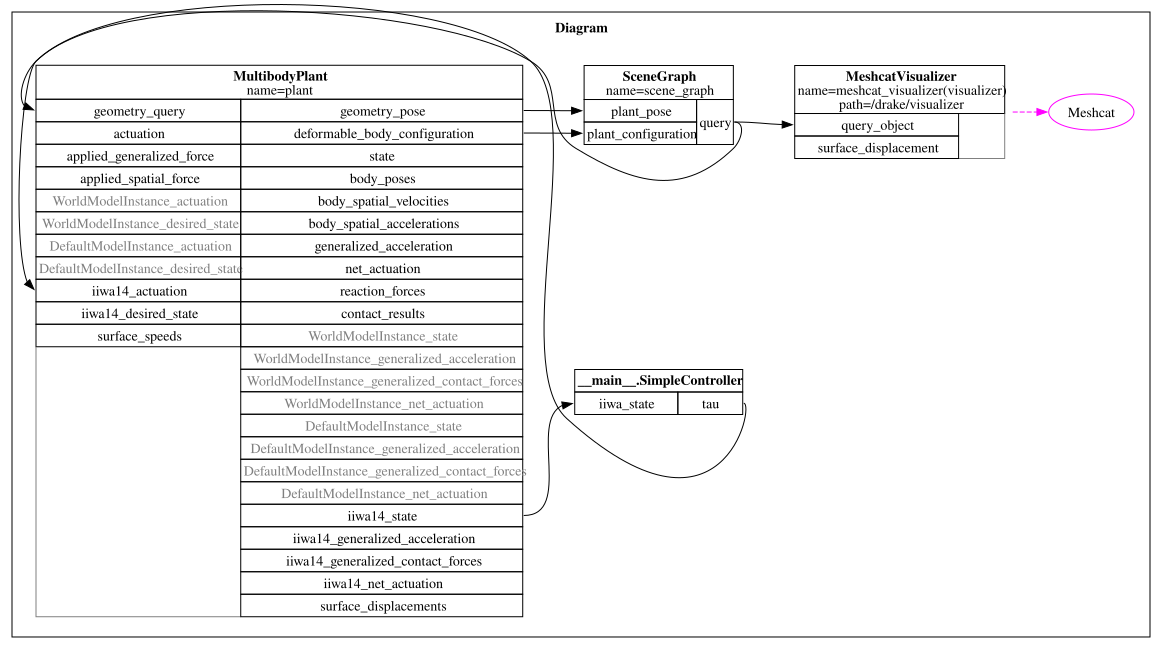

In [14]:
RenderDiagram(
    create_IIWA14_diagram_with_controller(10.0, np.array([1, 1, 0, 0, 0, 0, 0]))[0],
    max_depth=1,
)

Almost there! Now, just implement the `simulate_IIWA14` function again, but this time use your newly defined function `create_IIWA14_diagram_with_controller`:

In [15]:
def simulate_IIWA14_with_controller(
    q0: np.ndarray,
    controller_gain: float,
    q_desired: np.ndarray,
    simulation_time=3.0,
    set_target_realtime_rate=True,
) -> np.ndarray:
    diagram, plant, iiwa = create_IIWA14_diagram_with_controller(
        controller_gain, q_desired
    )

    context = diagram.CreateDefaultContext()
    plant_context = plant.GetMyMutableContextFromRoot(context)
    plant.SetPositions(plant_context, iiwa, q0)

    simulator = Simulator(diagram, context)
    if set_target_realtime_rate:
        simulator.set_target_realtime_rate(1.0)
    simulator.Initialize()
    simulator.AdvanceTo(simulation_time)

    return plant.GetPositions(plant_context).copy()


Amazing! Now let us run a simulation. How high do you have to set the gain to make the IIWA keep its starting configuration?

In [16]:
# Test your implementation
q_initial = np.array([0, 1.0, 0.3, 0.7, 0, 0, 0])

print("Starting robot simulation...")
print(f"Check your Meshcat window ({meshcat.web_url()}) to see the robot simulation!")
print("     - If the robot is not moving, the simulation already finished.")
print(
    "     - Try running this cell again (or increase the simulation time), with the meshcat window open!"
)
q_final = simulate_IIWA14_with_controller(
    q_initial,
    controller_gain=10,
    q_desired=q_initial,
    simulation_time=15 if running_as_notebook else 0.1,
    set_target_realtime_rate=running_as_notebook,
)

print("✅ Robot simulation completed!")
print(f"   Initial joint positions: {q_initial}")
print(f"   Final joint positions: {q_final}")

Starting robot simulation...
Check your Meshcat window (http://localhost:7001) to see the robot simulation!
     - If the robot is not moving, the simulation already finished.
     - Try running this cell again (or increase the simulation time), with the meshcat window open!


✅ Robot simulation completed!
   Initial joint positions: [0.  1.  0.3 0.7 0.  0.  0. ]
   Final joint positions: [-1.10493883e-03  1.03538891e+00  3.02274352e-01  7.05232626e-01
 -1.94864217e-04 -1.27212612e-03  5.27762827e-06]


**NOTE:** You will notice that this controller does not work very well. That is because we are only using a simple proportional controller (a "P-controller"), which only inputs a multiple of the tracking error. The purpose of this exercise is to teach you how to use Drake, but we will soon learn about much better control methods!

### VERIFICATION IN GRADESCOPE

Simulate your system with the following values, and copy/paste the final joint positions of the IIWA14:
- initial positions: $[0.2, 0.2, 0.2, 0, 0, 0, 0]$
- q_desired: $[0, 0, 0, 0, 0, 0, 0]$
- Controller gain: $120.0$
- Simulation time: $10 s$



In [17]:
q_final = simulate_IIWA14_with_controller(
    q0=np.array([0.2, 0.2, 0.2, 0, 0, 0, 0]),
    controller_gain=120.0,
    q_desired=np.zeros(7),
    simulation_time=10.0,
    set_target_realtime_rate=False,
)
print("Final joint positions:", q_final)


Final joint positions: [ 1.26317171e-02  8.13040566e-03 -5.72823579e-02 -2.43876159e-02
 -1.37802794e-04  4.71369969e-04 -2.97584254e-05]


---

## Part 3: Creating Custom Models with SDFormat

Let's learn how to create custom objects for simulation! In the previous two parts, we used a predefined SDFormat(`.sdf`) file to load the IIWA14. We'll now create a simple table from scratch using the same format, then we will use a provided API to generate more complicated assets (your own initials), and show you how to load both into your simulation.

**YOUR TASK:** 
1. Create a simple SDFormat model for a simple table from scratch
2. Use the provided API to generate URDF files for your initials

**Key Concepts:**
- `SDF`, `URDF`, `MJCF`: Three commonly used (and very similar) XML formats to describe robots and objects for simulation
- **Visual Geometry**: What you see in visualization (can be detailed)
- **Collision Geometry**: What physics engine uses for contact (should be simple)
- **Inertial Properties**: Mass and inertia for realistic physics behavior

**Reference:** For this part, we will be using the [Authoring a Multibody Simulation Tutorial](https://github.com/RobotLocomotion/drake/blob/master/tutorials/authoring_multibody_simulation.ipynb) - this part follows the **"Creating custom models"** section closely, where the tutorial shows how to create a cylinder model from an SDFormat string. You should skim through this section before you start the implementation below!


#### Step 1: Write the SDF file for a simple "table" from scratch

SDF, URDF, and MJCF files are not magic, and are in fact quite simple. Here you will write the SDF file for a simple "table" from scratch as an SDF file, showing you how to create your own assets in the future.

In the following cell we will define the SDF string in the code to make the homework cleaner, but usually these are saved to separate `.sdf` files that can be loaded into Drake. 

**WARNING:** The SDFormat is sensitive to indentation, so make sure to refer to the tutorial for how to indent things! You might also find it useful to refer to the [Official SDFormat Documentation](http://sdformat.org/tutorials)


In [18]:
table_sdf = """<?xml version="1.0"?>
<sdf version="1.7">
  <model name="table">
    <link name="table_link">
      <inertial>
        <pose>0 0 0 0 0 0</pose>
        <mass>1.0</mass>
        <inertia>
          <ixx>0.3341667</ixx>
          <ixy>0</ixy>
          <ixz>0</ixz>
          <iyy>0.3341667</iyy>
          <iyz>0</iyz>
          <izz>0.6666667</izz>
        </inertia>
      </inertial>
      <visual name="visual">
        <geometry><box><size>2 2 0.1</size></box></geometry>
      </visual>
      <collision name="collision">
        <geometry><box><size>2 2 0.1</size></box></geometry>
      </collision>
    </link>
  </model>
</sdf>
"""
print(table_sdf)


<?xml version="1.0"?>
<sdf version="1.7">
  <model name="table">
    <link name="table_link">
      <inertial>
        <pose>0 0 0 0 0 0</pose>
        <mass>1.0</mass>
        <inertia>
          <ixx>0.3341667</ixx>
          <ixy>0</ixy>
          <ixz>0</ixz>
          <iyy>0.3341667</iyy>
          <iyz>0</iyz>
          <izz>0.6666667</izz>
        </inertia>
      </inertial>
      <visual name="visual">
        <geometry><box><size>2 2 0.1</size></box></geometry>
      </visual>
      <collision name="collision">
        <geometry><box><size>2 2 0.1</size></box></geometry>
      </collision>
    </link>
  </model>
</sdf>



Great! If everything went as expected, we should now be able to visualize our custom asset. We will visualize it using Drake's built in `ModelVisualizer`, as illustrated in the tutorial (section "Creating Custom Models"). After writing the visualization code below, you should be able to see your table in the same Meshcat window as before!

**Note:** Make sure to click "Open Controls -> Stop Running" in MeshCat when you're done viewing (you will still be able to see the box, even though the visualization has stopped).


In [19]:
visualizer = ModelVisualizer(meshcat=meshcat)
visualizer.parser().AddModelsFromString(table_sdf, "sdf")
visualizer.Run(loop_once=True)


#### Step 2: Create a custom asset with your initials

In this step, you will create a custom asset from your initials. For this we have provided a library for you that generates `.sdf` files for a given letter, but the structure of the underlying files look exactly like the code snippet you wrote above for the simple table!

Here we have provided you with the code you need to run (it might take up to ~30 seconds to finish creating the letter files!). Feel free to change the font, the size and the extrusion depth!


In [20]:
# Let us save our files to a new folder called `assets` in the `Files`
# section on the left
output_dir = Path("assets/")

# TODO: Insert your initials here!
your_initials = "BPG"

for letter in your_initials:
    create_sdf_asset_from_letter(
        text=letter,
        font_name="DejaVu Sans",
        letter_height_meters=0.2,
        extrusion_depth_meters=0.07,
        output_dir=output_dir / f"{letter}_model",
    )

Great. Now, before we move on, you should have a look at the files that have been generated in the "file" section on the left under the folder named `assets/`, which looks like the following for a general `letter`:

```
{letter}_model/
├── {letter}_parts/
│   ├── convex_piece_000.obj
│   ├── convex_piece_001.obj
│   ├── convex_piece_002.obj
│   └── ... (more convex mesh files)
├── {letter}.obj
└── {letter}.sdf
```

For instance, for the letter `A`, it looks like:

```
A_model/
├── A_parts/
│   ├── convex_piece_000.obj
│   ├── convex_piece_001.obj
│   ├── convex_piece_002.obj
│   └── ... (more convex mesh files)
├── A.obj
└── A.sdf
```

The `.obj` file described the overall 3D mesh of the letter, and the `convex_piece_XXX.obj` files describe convex parts of the mesh for a letter: these are just text files that contain a list of vertices and faces. Try opening one of them in a text editor to see for yourself! 

The `.sdf` file contains the asset description for each individual letter, which links to the overall `.obj` file for the visual geometry, and the convex `.obj` files for the collision geometry (where each mesh part must be convex, which is why we generate multiple parts for each letter!).


Okay, great! Now that we have generated the letters, let us use Drake's `ModelVisualizer` and have a look at them! Fill in the missing code below, and make sure that the letters you generated look good.

**NOTE**: By clicking on `Scene > drake` you can enable visualization of `inertia` and `proximity` (collision geometry), which lets you see the physical properties of the asset too. This can be very handy when debugging!

In [21]:
letter_to_visualize = "B"
letter_path = f"assets/{letter_to_visualize}_model/{letter_to_visualize}.sdf"

visualizer = ModelVisualizer(meshcat=meshcat)
visualizer.parser().AddModels(letter_path)
visualizer.Run(loop_once=True)


---

## Part 4: Complete Simulation - Robot + Your Custom Asset

**The Grand Finale!** Now we'll combine everything you've learned to create a complete simulation with both the IIWA14 robot and your custom initials asset!

**YOUR TASK:** Build a physics simulation containing:
1. **IIWA14 robot**: welded to the world frame as before.
2. **Your custom table**: welded to the world frame near your robot (but not penetrating it!)
3. **Your custom initials**: placed on top of your custom table.

You now have all the tools you need to implement this yourself! Use the patterns you've learned from the previous parts to complete the notebook. When you are done, take a screen recording (must be an `.mp4` file with size below 500 MB) of the simulation and upload it to Gradescope.

**Final Goal:** Use a screen recording tool to record a video of your simulated scene. The video should show your initials falling onto the table, which is welded in place close to the robot (but not penetrating it).

**Hint**: `WeldFrames` takes a third argument a `RigidTransform` (which you will learn about later in the class). For now, you can just pass in a `(x,y,z)`-position with `RigidTransform([x,y,z])` to weld frames with an offset. (As always, if you are unsure about a function signature take a look at the [official documentation](https://drake.mit.edu/pydrake/pydrake.multibody.plant.html))


In [22]:
# Before you start, make sure to run the following cell to clear the meshcat window!
meshcat.Delete()
meshcat.DeleteAddedControls()

In [23]:
def simulate_full_system(
    initial_iiwa_positions: np.ndarray,
    initial_letter_poses: list[RigidTransform],
    table_pose: RigidTransform,
    simulation_time: float = 15.0,
) -> None:
    builder = DiagramBuilder()
    plant, scene_graph = AddMultibodyPlantSceneGraph(builder, time_step=1e-4)
    parser = Parser(plant)

    (iiwa,) = parser.AddModelsFromUrl(IIWA_URDF)
    plant.WeldFrames(plant.world_frame(), plant.GetFrameByName("iiwa_link_0", iiwa))

    table = parser.AddModelsFromString(table_sdf, "sdf")[0]
    plant.WeldFrames(
        plant.world_frame(), plant.GetFrameByName("table_link", table), table_pose
    )

    letters = []
    for letter in your_initials:
        model = parser.AddModels(f"assets/{letter}_model/{letter}.sdf")[0]
        letters.append((letter, model))

    MeshcatVisualizer.AddToBuilder(builder, scene_graph, meshcat)
    plant.Finalize()

    diagram = builder.Build()
    context = diagram.CreateDefaultContext()
    plant_context = plant.GetMyMutableContextFromRoot(context)

    plant.SetPositions(plant_context, iiwa, initial_iiwa_positions)
    for (letter, model), pose in zip(letters, initial_letter_poses):
        body = plant.GetRigidBodyByName(f"{letter}_body_link", model)
        plant.SetFreeBodyPose(plant_context, body, pose)

    plant.get_actuation_input_port(iiwa).FixValue(plant_context, np.zeros(7))

    simulator = Simulator(diagram, context)
    simulator.Initialize()
    simulator.AdvanceTo(simulation_time)


Run the code below to visualize your simulation!

**Tip:** If you ever want to download a recording of your simulation as a `.html` file, append `/download` to the meshcat URL in your browser. Go ahead and try it for your simulation below!

In [24]:
print(f"Meshcat URL: {meshcat.web_url()}")

# Notice that we have wrapped your function in a `meshcat.StartRecording()` and `meshcat.StopRecording()` block,
# followed by a `meshcat.PublishRecording()` call. This is a convenient way to make it possible to replay the
# simulation in meshcat after the simulation ends!
meshcat.StartRecording()
simulate_full_system(
    initial_iiwa_positions=np.array([-1.57, 0.1, 0, -1.2, 0, 1.6, 0]),
    initial_letter_poses=[
        # You can add rotations to the RigidTransform if you want, but we will learn more about that later!
        # The letters should be placed such that they are not in collision with each other, and such that
        # they fall onto the table.
        RigidTransform([0.7, 0.0, 1.0]),
        RigidTransform([0.9, 0.0, 1.0]),
        RigidTransform([1.1, 0.0, 1.0]),
    ],
    table_pose=RigidTransform(
        [0.5, 0.0, -0.05]
    ),  # this is a reasonable position for a 2m x 2m x 0.05m table, but feel free to change it!
    simulation_time=5.0 if running_as_notebook else 0.1,
)
meshcat.StopRecording()
meshcat.PublishRecording()

Meshcat URL: http://localhost:7001


# VERIFICATION IN GRADESCOPE
Congratulations! You are all done with this notebook. Now play the simulation back in your browser, and upload a screen recording of it in Gradescope (remember to make sure its an `mp4` file with size less than 500 MB).

---

# Congratulations!

You have successfully completed **Notebook 2: Physics Simulation and Robot Loading**!

### Summary

In this notebook, you learned to:

- Visualize robots, objects, and simulations using Meshcat
- Load real robots into Drake using `Parser` and robot description files (we worked only with SDF, but URDF and MJCF are pretty similar!)
- Understand Drake's physics simulation engine (`MultibodyPlant`) and geometry engine (`SceneGraph`)
- Create custom 3D assets and learn URDF/SDF authoring
- Build complete robot simulations with custom objects in Drake

You now have the foundational skills to work with Drake's physics simulation capabilities and create custom robotic environments. These skills will be essential for the more advanced topics later in the class, as well as for your class project!

**Next:** In Notebook 3, you will learn how to quickly assemble complex scenes using a `scenario.yaml` file and `HardwareStation`.

In [25]:
from manipulation.exercises.grader import Grader
from manipulation.exercises.intro.test_physics_simulation_and_robots import (
    TestPhysicsSimulationFullSystem,
)

Grader.grade_output([TestPhysicsSimulationFullSystem], [locals()], "results.json")
Grader.print_test_results("results.json")


Total score is 10/10.

Score for Test that simulate_full_system function runs without errors is 10/10.


In [26]:
from manipulation.exercises.grader import Grader
from manipulation.exercises.intro.test_physics_simulation_and_robots import (
    TestPhysicsSimulationVerification,
)

Grader.grade_output([TestPhysicsSimulationVerification], [locals()], "results.json")
Grader.print_test_results("results.json")


Total score is 20/20.

Score for Test the Gradescope verification exercise is 20/20.
